## 1. The data

**What it is:** Booking records from two hotels, one city hotel (79,330 rows) and one resort hotel (40,060 rows), with arrivals from July 2015 to August 2017. The data has 119,390 rows and 32 columns.

**Where it comes from:** Originally from the article "Hotel Booking Demand Datasets" (Antonio, Almeida & Nunes, *Data in Brief*, vol. 22, 2019). Downloaded and cleaned by Thomas Mock and Antoine Bichat for #TidyTuesday (2020), and obtained from Kaggle.

**What one row represents:** One booking. It records when the booking was made, the arrival date, the length of stay, the guests, the price and whether it was cancelled (`is_canceled`).

In [1]:
import pandas as pd

df = pd.read_csv("hotel_bookings.csv")

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [3]:
print(df.shape)
df.head(3)

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


## 2. Data quality (the five C's)

### Clean

In [4]:
df.head(5).T

,0,1,2,3,4
hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0,0,0
lead_time,342,737,7,13,14
arrival_date_year,2015,2015,2015,2015,2015
arrival_date_month,July,July,July,July,July
arrival_date_week_number,27,27,27,27,27
arrival_date_day_of_month,1,1,1,1,1
stays_in_weekend_nights,0,0,0,0,0
stays_in_week_nights,0,0,1,1,2
adults,2,2,1,1,2


In [5]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
print((nulos / len(df) * 100).round(3))
print(nulos)

print("Copias sobrantes:", df.duplicated().sum())
print("% del total:", round(df.duplicated().mean() * 100, 1))

company     94.307
agent       13.686
country      0.409
children     0.003
dtype: float64
company     112593
agent        16340
country        488
children         4
dtype: int64
Copias sobrantes: 31994
% del total: 26.8


**Finding:** Four columns have missing values: `company` (94.3%), `agent` (13.7%), `country` (0.4%) and `children` (4 rows). In addition, 31,994 rows (26.8%) are exact copies of another row. The data has no booking ID, so we cannot tell whether they are errors or real bookings.

We keep small repeats as real bookings, as an assumption we cannot verify without an ID. Large repeats (20,335 rows repeated 10 or more times, up to 180) look like blocks rather than independent decisions, so we analyse them below and keep one copy of each.

### Consistent

In [6]:
for col in ["meal", "market_segment", "distribution_channel"]:
    print(df[col].value_counts(), "\n")

print(df.loc[df["country"].isin(["CN", "CHN"]), "country"].value_counts(), "\n")

print(pd.crosstab(df["is_canceled"], df["reservation_status"]))

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64 

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64 

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64 

country
CN     1279
CHN     999
Name: count, dtype: int64 

reservation_status  Canceled  Check-Out  No-Show
is_canceled                                     
0                          0      75166        0
1                      43017          0     1207


**Finding:** Text labels have no case or spacing problems, but we found three inconsistencies. In `meal`, "Undefined" (1,169 rows) and "SC" (10,650 rows) mean the same thing according to the data dictionary: no meal package. `market_segment` (2 rows) and `distribution_channel` (5 rows) contain an undocumented "Undefined" label. China appears under two codes in `country`: `CN` (1,279 rows) and `CHN` (999 rows).

`is_canceled` fully agrees with `reservation_status`. The target includes 1,207 no-shows, so "cancelled" means "the guest did not stay".

### Current

In [7]:
fechas = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-"
    + df["arrival_date_month"] + "-"
    + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d"
)

print("Primera llegada:", fechas.min().date())
print("Última llegada:", fechas.max().date())

print(df.groupby("arrival_date_year")["is_canceled"].agg(["size", "mean"]).round(3))

Primera llegada: 2015-07-01
Última llegada: 2017-08-31
                    size   mean
arrival_date_year              
2015               21996  0.370
2016               56707  0.359
2017               40687  0.387


**Finding:** Arrivals run from 1 July 2015 to 31 August 2017, and only 2016 is a complete year. The data is about nine years old and predates COVID-19, so booking behaviour today may be different. The cancellation rate is similar across years (35.9% to 38.7%), although 2015 and 2017 are partial years.

Any recommendation assumes that these patterns still hold, so the model should be checked on recent bookings before the hotel uses it.

### Correct

In [8]:
print(df[["lead_time", "adults", "children", "babies", "adr"]].describe().T[["min", "max"]])

huespedes = df["adults"] + df["children"].fillna(0) + df["babies"]
noches = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

sin_huespedes = huespedes == 0
sin_noches = noches == 0
precio_negativo = df["adr"] < 0
precio_extremo = df["adr"] > 1000

print("Sin huéspedes:", sin_huespedes.sum())
print("Cero noches:", sin_noches.sum())
print("Precio negativo:", precio_negativo.sum())
print("Precio sobre 1000:", precio_extremo.sum())
print("Con algún defecto:", (sin_huespedes | sin_noches | precio_negativo | precio_extremo).sum())

print("Precio cero:", (df["adr"] == 0).sum())
print("10 adultos o más:", (df["adults"] >= 10).sum())

            min     max
lead_time  0.00   737.0
adults     0.00    55.0
children   0.00    10.0
babies     0.00    10.0
adr       -6.38  5400.0
Sin huéspedes: 180
Cero noches: 715
Precio negativo: 1
Precio sobre 1000: 1
Con algún defecto: 827
Precio cero: 1959
10 adultos o más: 13


**Finding:** 827 rows (0.7%) have impossible or highly doubtful values: 180 bookings with no guests, 715 with zero nights, one negative price (-6.38) and one price of 5,400 when the next highest is 510. Some rows have more than one defect. We will remove them during data preparation.

We keep the 1,959 bookings with a price of 0, because 680 of them are complimentary stays and a price of 0 is not impossible. We also keep the 13 bookings with 10 or more adults, because they could be groups. All 13 were cancelled.

### Comprehensive

In [9]:
print(df.groupby("hotel")["is_canceled"].agg(["size", "mean"]).round(3), "\n")
print(df["market_segment"].value_counts(normalize=True).round(3).head(4), "\n")
print(df["country"].value_counts(normalize=True).round(3).head(3), "\n")
print("Huéspedes repetidos:", round(df["is_repeated_guest"].mean(), 3))

               size   mean
hotel                     
City Hotel    79330  0.417
Resort Hotel  40060  0.278 

market_segment
Online TA        0.473
Offline TA/TO    0.203
Groups           0.166
Direct           0.106
Name: proportion, dtype: float64 

country
PRT    0.409
GBR    0.102
FRA    0.088
Name: proportion, dtype: float64 

Huéspedes repetidos: 0.032


**Finding:** The data covers only two hotels, and they behave differently: 41.7% of City Hotel bookings and 27.8% of Resort Hotel bookings were cancelled. Results may not apply to other hotels. Online travel agents account for 47.3% of bookings, Portugal for 40.9%, and only 3.2% of guests are repeat guests.

The data does not include a booking ID, hotel costs, cancellation reasons, competitor prices or whether a cancelled room was resold. The last gap matters most: we cannot observe the money actually lost per cancellation, so any business estimate will need a stated assumption.

## 3. Missing data

In [10]:
print(df[["agent", "company"]].isna().groupby(df["market_segment"]).mean().round(3), "\n")

for col in ["agent", "company", "country", "children"]:
    nulo = df[col].isna()
    print(col, "| cancelan con nulo:", round(df.loc[nulo, "is_canceled"].mean(), 3),
          "| sin nulo:", round(df.loc[~nulo, "is_canceled"].mean(), 3))

print("\nNulos en country por hotel:")
print(df.groupby("hotel")["country"].apply(lambda s: s.isna().sum()))
print(df.loc[df["country"].isna(), "reservation_status"].value_counts(), "\n")

raras = df["children"].isna() | (df["market_segment"] == "Undefined") | (df["distribution_channel"] == "Undefined")
print(df.loc[raras, ["hotel", "arrival_date_year", "market_segment", "distribution_channel", "children", "is_canceled"]])

                agent  company
market_segment                
Aviation        0.895    0.105
Complementary   0.861    0.579
Corporate       0.868    0.156
Direct          0.477    0.983
Groups          0.209    0.930
Offline TA/TO   0.016    0.996
Online TA       0.006    0.998
Undefined       1.000    1.000 

agent | cancelan con nulo: 0.247 | sin nulo: 0.39
company | cancelan con nulo: 0.382 | sin nulo: 0.175
country | cancelan con nulo: 0.137 | sin nulo: 0.371
children | cancelan con nulo: 1.0 | sin nulo: 0.37

Nulos en country por hotel:
hotel
City Hotel       24
Resort Hotel    464
Name: country, dtype: int64
reservation_status
Check-Out    421
Canceled      63
No-Show        4
Name: count, dtype: int64 

              hotel  arrival_date_year market_segment distribution_channel  \
14594  Resort Hotel               2015         Direct            Undefined   
40600    City Hotel               2015      Undefined            Undefined   
40667    City Hotel               2015        

For each column, the likely origin comes first, followed by the treatment. These are inferences from the data, not confirmed facts.

- **`company` (94.3%):** Most likely blank because no company made or paid for the booking (99.8% blank for online travel agents, 15.6% for corporate bookings), so we replace it with a `has_company` flag instead of filling in the ID.
- **`agent` (13.7%):** Most likely blank because no travel agency was involved (0.6% blank for online travel agents, 86.8% for corporate bookings), so we replace it with a `has_agent` flag instead of filling in the ID.
- **`country` (0.4%):** Probably not recorded, since 464 of the 488 blanks come from the resort hotel and these bookings cancel far less (13.7% vs 37.1%), so we label them "Unknown" and keep the rows to avoid biasing the data.
- **`children` (4 rows) and "Undefined" in `market_segment` (2) and `distribution_channel` (5):** Probably a recording failure, since they all fall within the same 5 rows, so we remove those 5 rows.

## 4. Framing

In [11]:
print(df["is_canceled"].value_counts(normalize=True).round(3), "\n")

revisar = {
    "Con estacionamiento": df["required_car_parking_spaces"] > 0,
    "Con pedidos especiales": df["total_of_special_requests"] > 0,
    "Con cambios": df["booking_changes"] > 0,
    "Otra pieza asignada": df["reserved_room_type"] != df["assigned_room_type"],
    "País PRT": df["country"] == "PRT",
    "Depósito Non Refund": df["deposit_type"] == "Non Refund",
}

for nombre, filtro in revisar.items():
    print(nombre, "| filas:", filtro.sum(), "| cancelan:", round(df.loc[filtro, "is_canceled"].mean(), 3))

non_refund = df[df["deposit_type"] == "Non Refund"]
print("\nNon Refund de PRT:", round((non_refund["country"] == "PRT").mean(), 3))
print("Non Refund con filas idénticas:", round(non_refund.duplicated(keep=False).mean(), 3))

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64 

Con estacionamiento | filas: 7416 | cancelan: 0.0
Con pedidos especiales | filas: 49072 | cancelan: 0.217
Con cambios | filas: 18076 | cancelan: 0.157
Otra pieza asignada | filas: 14917 | cancelan: 0.054
País PRT | filas: 48590 | cancelan: 0.566
Depósito Non Refund | filas: 14587 | cancelan: 0.994

Non Refund de PRT: 0.972
Non Refund con filas idénticas: 0.981


**Decision:** Which bookings are likely to be cancelled, so that the hotel can contact or confirm them in time?

**Target:** `is_canceled` (1 = cancelled or no-show, 0 = stayed). This is a binary classification problem.

**Unit of observation:** One booking.

**Prediction moment:** When the booking is confirmed, so we only use information available at that point.

**Baseline:** In the original data, 63.0% of bookings are not cancelled. After data preparation this rises to 71.1%, so always predicting "not cancelled" reaches 71.1% accuracy with 0% recall. Any model must beat this, and we do not judge models by accuracy alone.

**Leakage check:** For each column we asked whether it would exist, with this value, at the prediction moment.
- **Removed because they reveal the outcome or are recorded later:** `reservation_status`, `reservation_status_date`, `booking_changes`, `assigned_room_type`.
- **Removed because their timing is unknown:** `required_car_parking_spaces` (0% cancellation across 7,416 bookings), `total_of_special_requests`.
- **Removed as a precaution:** `country` may be corrected at check-in, since 86% of its blanks ended in check-out (63% overall). The evidence is weak: `PRT` cancels 56.6%, but only 35.7% without duplicates. It also has 177 values, 81 of them with fewer than 10 bookings.
- **Excluded from the main model:** `deposit_type`. "Non Refund" bookings cancel 99.4% of the time, which is implausible for customers who paid in full, and 97.2% come from `PRT`, so this looks like a data artifact. We will test the model with `deposit_type` and `country` added and report the difference.
- **Kept, with an assumption:** `adr`, assuming the price is agreed at booking.
- **Excluded, but not leakage:** `arrival_date_year`, because the hotel would use the model on future years that are not in the data. Month and week stay, since they repeat every year.

### Duplicates

       filas  cancelan  non_refund
veces                             
1      79225     0.262       0.003
2      10068     0.342       0.020
3       2907     0.351       0.032
4-5     3363     0.402       0.062
6-9     3492     0.406       0.119
10-19   6628     0.656       0.460
20-49   9588     0.831       0.714
50+     4119     0.949       0.852


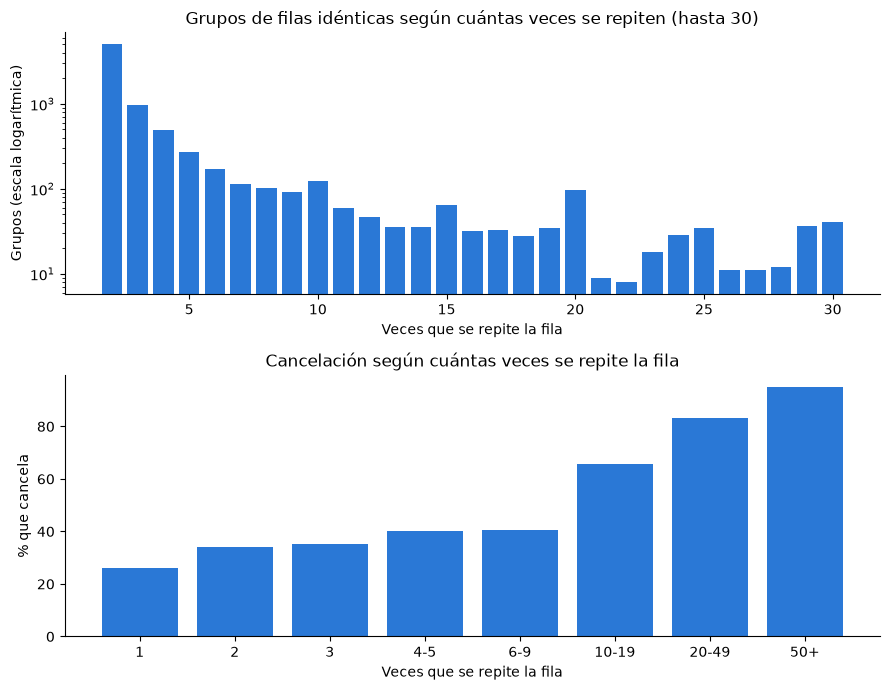

In [12]:
import matplotlib.pyplot as plt

repeticiones = df.groupby(list(df.columns), dropna=False)["hotel"].transform("size").rename("veces")

grupos = df.groupby(list(df.columns), dropna=False).size().value_counts().sort_index()
grupos = grupos[(grupos.index >= 2) & (grupos.index <= 30)]

tramos = pd.cut(
    repeticiones,
    bins=[0, 1, 2, 3, 5, 9, 19, 49, 200],
    labels=["1", "2", "3", "4-5", "6-9", "10-19", "20-49", "50+"]
)
tabla = df.groupby(tramos, observed=True).agg(
    filas=("is_canceled", "size"),
    cancelan=("is_canceled", "mean"),
    non_refund=("deposit_type", lambda s: (s == "Non Refund").mean()),
)
print(tabla.round(3))

fig, ejes = plt.subplots(2, 1, figsize=(9, 7))

ejes[0].bar(grupos.index, grupos.values, color="#2a78d6")
ejes[0].set_yscale("log")
ejes[0].set_title("Grupos de filas idénticas según cuántas veces se repiten (hasta 30)")
ejes[0].set_xlabel("Veces que se repite la fila")
ejes[0].set_ylabel("Grupos (escala logarítmica)")

ejes[1].bar(tabla.index.astype(str), tabla["cancelan"] * 100, color="#2a78d6")
ejes[1].set_title("Cancelación según cuántas veces se repite la fila")
ejes[1].set_xlabel("Veces que se repite la fila")
ejes[1].set_ylabel("% que cancela")

for eje in ejes:
    eje.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [13]:
detalle = df.assign(veces=repeticiones).groupby("veces").agg(
    filas=("is_canceled", "size"),
    cancelan=("is_canceled", "mean"),
    non_refund=("deposit_type", lambda s: (s == "Non Refund").mean()),
)
detalle["grupos"] = detalle["filas"] // detalle.index
print(detalle.loc[1:20].round(3).to_string())

       filas  cancelan  non_refund  grupos
veces                                     
1      79225     0.262       0.003   79225
2      10068     0.342       0.020    5034
3       2907     0.351       0.032     969
4       1988     0.400       0.054     497
5       1375     0.404       0.073     275
6       1026     0.427       0.117     171
7        805     0.374       0.061     115
8        824     0.398       0.155     103
9        837     0.419       0.140      93
10      1230     0.740       0.439     123
11       660     0.400       0.200      60
12       564     0.681       0.404      47
13       468     0.444       0.444      36
14       504     0.639       0.444      36
15       960     0.828       0.609      64
16       512     0.438       0.312      32
17       561     0.788       0.636      33
18       504     0.607       0.429      28
19       665     0.743       0.600      35
20      1940     0.938       0.794      97


**Finding:** We examined how often rows repeat to decide where to start removing copies. Up to 9 repetitions, cancellation stays between 34% and 41%. From 10 repetitions it jumps to 66% and reaches 95% at 50 or more, while "Non Refund" rises from 12% to 46% and then 85%. Peaks at round numbers (10, 15, 20) suggest deliberate blocks rather than coincidence. We therefore keep one copy of each row repeated 10 or more times, treating each block as one decision. Smaller repeats are kept. The cutoff is our judgement, but moving it between 3 and 10 changes the baseline by less than one point (72.0% to 71.1%).

### Data preparation

In [14]:
huespedes = df["adults"] + df["children"].fillna(0) + df["babies"]
noches = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

malas = (
    (huespedes == 0)
    | (noches == 0)
    | (df["adr"] < 0)
    | (df["adr"] > 1000)
    | df["children"].isna()
    | (df["market_segment"] == "Undefined")
    | (df["distribution_channel"] == "Undefined")
)

copia_sobrante = (repeticiones >= 10) & df.duplicated()
df_limpio = df[~malas & ~copia_sobrante].copy()

df_limpio["meal"] = df_limpio["meal"].replace("Undefined", "SC")
df_limpio["country"] = df_limpio["country"].replace("CN", "CHN").fillna("Unknown")

df_limpio["has_agent"] = df_limpio["agent"].notna().astype(int)
df_limpio["has_company"] = df_limpio["company"].notna().astype(int)
df_limpio = df_limpio.drop(columns=["agent", "company"])

print("Copias sacadas:", copia_sobrante.sum())
print("Filas sacadas:", malas.sum())
print("Tamaño:", df_limpio.shape)
print("Nulos que quedan:", df_limpio.isna().sum().sum())
print("Cancelan:", round(df_limpio["is_canceled"].mean(), 3))

Copias sacadas: 19421
Filas sacadas: 832
Tamaño: (99156, 32)
Nulos que quedan: 0
Cancelan: 0.289


**Result:** We removed 20,234 rows: 19,421 extra copies of rows repeated 10 or more times, and 832 rows with doubtful values or recording failures (19 rows fall in both groups). Smaller repeats are kept. We merged "Undefined" into "SC" in `meal` and `CN` into `CHN` in `country`, labelled missing countries as "Unknown", and replaced `agent` and `company` with `has_agent` and `has_company`. The clean data has 99,156 rows and no missing values, and 28.9% of bookings are cancelled, so the baseline is 71.1%.

## 5. Models compared against a baseline

**Features and split:** We keep only the columns that pass the leakage check in section 4. Then we split the data once into 70% train and 30% test, with a fixed seed. Identical rows always stay on the same side, so the model is never tested on a row it already saw. The baseline and both models use this same split.

In [15]:
columnas_fuera = [
    "reservation_status",
    "reservation_status_date",
    "booking_changes",
    "assigned_room_type",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "country",
    "deposit_type",
    "arrival_date_year",
]

X = df_limpio.drop(columns=columnas_fuera + ["is_canceled"])
y = df_limpio["is_canceled"]

print("X:", X.shape)
print("y:", y.shape)
print(list(X.columns))

X: (99156, 22)
y: (99156,)
['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'days_in_waiting_list', 'customer_type', 'adr', 'has_agent', 'has_company']


In [16]:
from sklearn.model_selection import GroupShuffleSplit

grupo = X.groupby(list(X.columns)).ngroup()

separador = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
idx_train, idx_test = next(separador.split(X, y, groups=grupo))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print("Train:", X_train.shape, "| cancelan:", round(y_train.mean(), 3))
print("Test:", X_test.shape, "| cancelan:", round(y_test.mean(), 3))
print("Grupos en ambos lados:", len(set(grupo.iloc[idx_train]) & set(grupo.iloc[idx_test])))
print("Baseline en test:", round(1 - y_test.mean(), 3))

Train: (69333, 22) | cancelan: 0.29
Test: (29823, 22) | cancelan: 0.286
Grupos en ambos lados: 0
Baseline en test: 0.714


**Result:** The model sees 22 columns. After removing columns, 27,682 rows have an identical twin, and none of them is split between train and test. Train has 69,333 rows and test 29,823. Cancellation is similar in both parts (29.0% and 28.6%), so the baseline on the test set is 71.4%.

### Baseline and logistic regression

We compare two approaches on the same test set. The baseline always predicts "not cancelled". The logistic regression is an interpretable model that turns each column into a weight. Text columns are one-hot encoded and numeric columns are scaled inside a pipeline, so these steps are fitted on the training data only.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

columnas_texto = X_train.select_dtypes(exclude="number").columns.tolist()
columnas_numero = X_train.select_dtypes(include="number").columns.tolist()

preparar = ColumnTransformer([
    ("texto", OneHotEncoder(handle_unknown="ignore"), columnas_texto),
    ("numero", StandardScaler(), columnas_numero),
])

baseline = DummyClassifier(strategy="most_frequent")
logistica = Pipeline([
    ("preparar", preparar),
    ("modelo", LogisticRegression(max_iter=1000)),
])

baseline.fit(X_train, y_train)
logistica.fit(X_train, y_train)


def medir(nombre, modelo):
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    return {
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "auc": roc_auc_score(y_test, prob),
    }


resultados = pd.DataFrame([
    medir("Baseline", baseline),
    medir("Logistic regression", logistica),
]).set_index("modelo")
print(resultados.round(3))

                     accuracy  precision  recall     f1    auc
modelo                                                        
Baseline                0.714       0.00   0.000  0.000  0.500
Logistic regression     0.744       0.66   0.215  0.325  0.731


**Result:** The logistic regression beats the baseline on accuracy (74.4% vs 71.4%) and AUC (0.731 vs 0.500). When it flags a cancellation it is right 66% of the time, but at the default 0.5 threshold it only finds 21.5% of cancellations. The baseline finds none.

### Random forest

The second model family is a random forest: many decision trees that each learn rules from a different sample of the data and then vote. Unlike the logistic regression, it can capture combinations of columns. To stop it from memorising the training data, each rule must cover at least 5 bookings (`min_samples_leaf=5`).

In [18]:
from sklearn.ensemble import RandomForestClassifier

preparar_bosque = ColumnTransformer([
    ("texto", OneHotEncoder(handle_unknown="ignore"), columnas_texto),
], remainder="passthrough")

bosque = Pipeline([
    ("preparar", preparar_bosque),
    ("modelo", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)),
])
bosque.fit(X_train, y_train)

resultados = pd.DataFrame([
    medir("Baseline", baseline),
    medir("Logistic regression", logistica),
    medir("Random forest", bosque),
]).set_index("modelo")
print(resultados.round(3))

                     accuracy  precision  recall     f1    auc
modelo                                                        
Baseline                0.714      0.000   0.000  0.000  0.500
Logistic regression     0.744      0.660   0.215  0.325  0.731
Random forest           0.763      0.681   0.321  0.436  0.782
